# 09 · How high can AUC go? (generator study, phase 1)

**Question:** is the leader's 0.738 reachable with these data, or is the gap to our 0.723 mostly leaderboard noise? This decides whether reverse-engineering the generator (phases 2–4) is worth it.

**Why not simulate from our own probabilities:** drawing labels y* ~ Bernoulli(p̂) and scoring p̂ against them returns the model's own AUC for any calibrated model, so it says nothing about the true ceiling. Instead:
1. **Calibration** of the best model's OOF predictions (needed to read the rest).
2. **Leaderboard noise:** how much one AUC moves on a public-size sample, and how much a *difference* between two models moves.
3. **Learning curve:** train on 25 %–100 % of each training fold (same scored folds) and extrapolate AUC to unlimited data. That is the ceiling for this model family and features, plus the expected gain of the final refit on 25 % more data.

Best model = `07` CatBoost (41 features + 4 one-hot copies), 15-fold CV AUC 0.7143.

In [1]:
import json, sys
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from sklearn.metrics import roc_auc_score
sys.path.insert(0, '.')
import common as C, features as FE

lab, hold = C.load()
S = FE.add_static(lab)
L = FE.add_cats(S)
PC = json.load(open('params_cats.json')); F0, P0 = PC['features'], PC['params']
TU = json.load(open('params_tuned.json'))['cb']
y = lab[C.TARGET].to_numpy()
best = C.cv_score('cats15___copies__ohm_10', L, F0, 'cb', P0, notes='07_catboost_cats')                       # cached (07)
prev = C.cv_score('ens_cb_s42', S, TU['features'], 'cb', TU['params'] | {'random_seed': 42}, rounds=TU['rounds'])  # cached (05): LB 0.723 model
p, p_prev = best['oof_all'][0], prev['oof_all'][0]          # one CV repeat = genuine out-of-fold predictions for every row
print(f'best model OOF AUC (repeat 0) {roc_auc_score(y, p):.4f} | previous (LB 0.723) {roc_auc_score(y, p_prev):.4f}')

best model OOF AUC (repeat 0) 0.7139 | previous (LB 0.723) 0.7126


## 1. Calibration

In [2]:
t = C.deciles(y, p)
z = np.log(p / (1 - p))
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(C=1e6).fit(z.reshape(-1, 1), y)
print(f'calibration slope {lr.coef_[0][0]:.2f} (1 = ideal; <1 = over-confident), intercept {lr.intercept_[0]:+.2f} | '
      f'mean prediction {p.mean():.3f} vs base rate {y.mean():.3f}')
t.style.format({'observed': '{:.1%}', 'predicted': '{:.1%}', 'lift': '{:.2f}', 'cum. capture': '{:.0%}'})

calibration slope 1.15 (1 = ideal; <1 = over-confident), intercept +0.29 | mean prediction 0.111 vs base rate 0.112


,quotes,converted,observed,predicted,lift,cum. capture
decile,,,,,,
1,2950,896.000000,30.4%,27.4%,2.72,27%
2,2949,540.000000,18.3%,17.9%,1.64,44%
3,2950,428.000000,14.5%,14.4%,1.30,57%
4,2949,367.000000,12.4%,12.0%,1.11,68%
5,2950,280.000000,9.5%,10.1%,0.85,76%
6,2949,244.000000,8.3%,8.6%,0.74,84%
7,2950,196.000000,6.6%,7.2%,0.59,90%
8,2949,158.000000,5.4%,5.9%,0.48,94%
9,2950,113.000000,3.8%,4.6%,0.34,98%


## 2. Leaderboard noise
The holdout has 7,375 quotes; the public leaderboard scores an unknown share of them. AUC spread on random subsets of the labeled OOF predictions at typical public shares:

In [3]:
rng = np.random.default_rng(0)
rows = []
for share in (0.25, 0.5, 1.0):
    n = int(7375 * share)
    a, dlt = [], []
    for _ in range(2000):
        i = rng.choice(len(y), n, replace=False)
        a.append(roc_auc_score(y[i], p[i])); dlt.append(a[-1] - roc_auc_score(y[i], p_prev[i]))
    a, dlt = np.array(a), np.array(dlt)
    rows.append({'public share': f'{share:.0%}', 'quotes': n, 'AUC sd': a.std(), 'AUC 95% range': f'{np.quantile(a, .025):.3f}–{np.quantile(a, .975):.3f}',
                 'P(AUC ≥ mean + 0.015)': (a >= a.mean() + 0.015).mean(),
                 'Δ best − previous: mean': dlt.mean(), 'Δ sd': dlt.std(), 'P(Δ < 0)': (dlt < 0).mean()})
noise = pd.DataFrame(rows).set_index('public share')
noise.style.format({'AUC sd': '{:.4f}', 'P(AUC ≥ mean + 0.015)': '{:.1%}', 'Δ best − previous: mean': '{:+.4f}', 'Δ sd': '{:.4f}', 'P(Δ < 0)': '{:.1%}'})

,quotes,AUC sd,AUC 95% range,P(AUC ≥ mean + 0.015),Δ best − previous: mean,Δ sd,P(Δ < 0)
public share,,,,,,,
25%,1843,0.0184,0.675–0.750,20.1%,+0.0012,0.0029,33.1%
50%,3687,0.0126,0.689–0.738,11.3%,+0.0013,0.0021,25.1%
100%,7375,0.0082,0.697–0.730,3.2%,+0.0014,0.0013,15.6%


**Reading:**
- **One public score is very noisy.** If the public leaderboard is half the holdout (~3,700 quotes), a model's AUC has sd ≈ 0.013 there; the 95% range spans 0.689–0.738 for the *same* model. Our 0.723 vs ~0.716 expected (CV + refit gain) is half an sd.
- **The leader's 0.738 is not strong evidence of a better model.** A single model lands ≥ 0.015 above its true AUC 11% of the time at a 50% public share (20% at 25%). The top of a leaderboard is the maximum over many teams and submissions, so it's expected to sit ~2 sd above the true level.
- **Comparing our own uploads:** `catboost_cats5` should beat `catboost_tuned5` by only ~+0.0013 on the public set, with sd 0.0021, so there's a **~25% chance it shows a lower public score** even though it's better. Judge it by CV, not by that one comparison.

## 3. Learning curve
Each training fold is subsampled (stratified) to a fraction of its 23,597 rows; the scored folds are unchanged, so every point is paired with the same 15 test folds. Tree count is re-chosen per fraction (best mean-AUC iteration). Fit: AUC(n) = A∞ − b·n^(−c), with a fold bootstrap for the uncertainty in A∞.

,train rows,AUC,se,trees
15%,3539,0.6791,0.0037,189
25%,5899,0.6922,0.0040,248
40%,9438,0.7015,0.0040,240
60%,14158,0.7070,0.0040,280
80%,18877,0.7108,0.0038,294
100%,23596,0.7143,0.0036,402


A∞ = 0.7346 (90% bootstrap 0.7252–0.7695), exponent c = 0.51
predicted AUC at 23,597 rows (CV) 0.7137 → at 29,496 rows (final refit) 0.7160 (+0.0023); at 2× data 0.7216


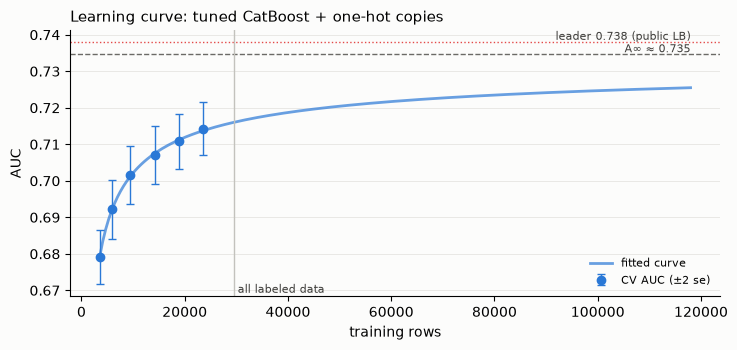

In [4]:
def sub_fn(frac):
    def fn(tr, sc):
        return tr.groupby(C.TARGET, group_keys=False).sample(frac=frac, random_state=0), sc
    fn.tag = f'sub{frac}'
    return fn

FRACS = [0.15, 0.25, 0.4, 0.6, 0.8]
curve = {f: C.cv_score(f'lc_{f}', L, F0, 'cb', P0, fold_fn=sub_fn(f), notes='09 learning curve') for f in FRACS} | {1.0: best}
n_train = len(y) * 0.8
N = np.array([f * n_train for f in curve])
A = np.array([r['fold_aucs'] for r in curve.values()])           # (fractions x 15 folds)
lc = pd.DataFrame({'train rows': N.astype(int), 'AUC': A.mean(1), 'se': A.std(1) / np.sqrt(15), 'trees': [r['rounds'] for r in curve.values()]},
                  index=[f'{f:.0%}' for f in curve])
display(lc.style.format({'AUC': '{:.4f}', 'se': '{:.4f}'}))

f = lambda n, a, b, c: a - b * n ** (-c)
def fit(aucs):
    return curve_fit(f, N, aucs, p0=[0.72, 1.0, 0.5], bounds=([0.5, 0, 0.05], [1, 1e4, 3]), maxfev=20000)[0]
a_inf, b, c = fit(A.mean(1))
boot = []
for _ in range(500):
    j = rng.integers(0, 15, 15)
    try:
        boot.append(fit(A[:, j].mean(1)))
    except RuntimeError:
        pass
boot = np.array(boot)
full = len(y)
print(f'A∞ = {a_inf:.4f} (90% bootstrap {np.quantile(boot[:, 0], .05):.4f}–{np.quantile(boot[:, 0], .95):.4f}), exponent c = {c:.2f}')
print(f'predicted AUC at 23,597 rows (CV) {f(n_train, a_inf, b, c):.4f} → at {full:,} rows (final refit) {f(full, a_inf, b, c):.4f} '
      f'(+{f(full, a_inf, b, c) - f(n_train, a_inf, b, c):.4f}); at 2× data {f(2 * full, a_inf, b, c):.4f}')

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.errorbar(N, A.mean(1), yerr=2 * A.std(1) / np.sqrt(15), fmt='o', color='#2a78d6', ms=6, capsize=3, lw=1, label='CV AUC (±2 se)')
grid = np.linspace(N.min(), 4 * full, 200)
ax.plot(grid, f(grid, a_inf, b, c), color='#2a78d6', lw=2, alpha=0.7, label='fitted curve')
ax.axhline(a_inf, color='#6b6a66', lw=1, ls='--'); ax.text(grid[-1], a_inf + 0.0006, f'A∞ ≈ {a_inf:.3f}', ha='right', fontsize=8, color='#3d3c39')
ax.axhline(0.738, color='#e34948', lw=1, ls=':'); ax.text(grid[-1], 0.738 + 0.0006, 'leader 0.738 (public LB)', ha='right', fontsize=8, color='#3d3c39')
ax.axvline(full, color='#c3c2bd', lw=1); ax.text(full, ax.get_ylim()[0] + 0.001, ' all labeled data', fontsize=8, color='#3d3c39')
ax.set_xlabel('training rows'); ax.set_ylabel('AUC'); ax.legend(frameon=False, fontsize=8, loc='lower right')
for s in ('top', 'right'): ax.spines[s].set_visible(False)
ax.grid(axis='y', color='#e6e5e1', lw=0.6); ax.set_axisbelow(True)
ax.set_title('Learning curve: tuned CatBoost + one-hot copies', loc='left', fontsize=11)
fig.patch.set_facecolor('#fcfcfb'); ax.set_facecolor('#fcfcfb'); fig.tight_layout()
fig.savefig('figures/09_learning_curve.png', dpi=150, facecolor=fig.get_facecolor()); plt.show()

**Reading:**
- **The curve is still climbing steeply** (≈ n^−0.5): 0.679 at 3.5k rows → 0.714 at 23.6k. Extrapolated ceiling for this model and these features: **A∞ ≈ 0.735** (90% bootstrap 0.725–0.77, wide because it's an extrapolation).
- **The final refit on all 29.5k rows should add ~+0.0023** over CV (expected holdout ≈ 0.716), which explains part of why the leaderboard reads above CV.
- **The model is data-limited, not feature-limited.** Given the same features, more data would keep improving it, so the missing AUC is in *how efficiently* the model learns the signal: CatBoost must discover each effect's shape from noisy data. A model with the generator's correct functional form (thresholds, bands, the right interactions) needs far less data, and could plausibly move toward the ceiling. That's the case for phase 3.

## Conclusions
- **Calibration:** good on average (mean 11.1% vs 11.2%) but slightly **under-confident** (slope 1.15): top decile predicted 27.4% vs observed 30.4%, bottom 3.1% vs 2.5%. The strong regularization shrinks predictions toward the mean, which is consistent with a data-limited model.
- **Leaderboard:** a public score has sd ≈ 0.013 (50% share). The gap to 0.738 is within noise for a leaderboard maximum; it's not evidence that a missing feature exists.
- **Ceiling:** the learning curve extrapolates to **~0.735** for this model family, well above the current 0.714 CV. The headroom is in learning efficiency, not in new columns.
- **Implication for phases 2–4:** worthwhile. Recovering the generator's exact functional forms (phase 3) is the most direct way to use the data more efficiently. Cheaper proxies: stronger structural priors in the GBM (monotone constraints, interaction constraints) and parametric features that encode recovered shapes.